# Домашняя работа 7.1. Остывание стержня
## Зелёный уровень

$$
u_t=u_{xx},\quad x\in[0,1],\qquad u(0,t)=u(1,t)=0,
$$

$$
u(x,0)=\sin(\pi x)+0.3\sin(5\pi x).
$$

Точное решение:

$$
u(x,t)=e^{-\pi^2t}\sin(\pi x)+0.3e^{-25\pi^2t}\sin(5\pi x).
$$

Используются сетки с 25, 50 и 100 интервалами, то есть с 26, 51 и 101 узлом
включая оба конца. Для запуска нужны NumPy и Matplotlib.
[Условие задания](https://github.com/yartmihant/Students6Year2026#readme).

## 1. Явная и неявная схемы

Схема FTCS во внутренних узлах:

$$
u_j^{n+1}=u_j^n+r(u_{j-1}^n-2u_j^n+u_{j+1}^n).
$$

Неявный Эйлер:

$$
-r u_{j-1}^{n+1}+(1+2r)u_j^{n+1}-r u_{j+1}^{n+1}=u_j^n.
$$

Здесь $r=\Delta t/\Delta x^2=0.4$, что удовлетворяет условию устойчивости FTCS
$r\leq1/2$. Трёхдиагональная система неявной схемы решается прогонкой.
Граничные значения на каждом слое равны нулю.

Заданные моменты не всегда совпадают с временной сеткой. Во всех шагах сохраняется
$r=0.4$, а профиль в нужный момент линейно интерполируется между соседними слоями.
Его дополнительная ошибка $O(\Delta t^2)=O(\Delta x^4)$ не меняет ожидаемого
второго порядка при $\Delta t=0.4\Delta x^2$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.25})

r = 0.4
sizes = [25, 50, 100]
targets = [0.001, 0.01, 0.1]


def exact(x, t):
    return np.exp(-np.pi**2*t)*np.sin(np.pi*x) + 0.3*np.exp(-25*np.pi**2*t)*np.sin(5*np.pi*x)


def factors(size):
    diagonal = np.full(size, 1 + 2*r)
    multipliers = np.zeros(size)
    for j in range(1, size):
        multipliers[j] = -r / diagonal[j-1]
        diagonal[j] += r * multipliers[j]
    return diagonal, multipliers


def implicit_step(values, diagonal, multipliers):
    right = values.copy()
    for j in range(1, len(right)):
        right[j] -= multipliers[j] * right[j-1]
    result = np.empty_like(right)
    result[-1] = right[-1] / diagonal[-1]
    for j in range(len(right)-2, -1, -1):
        result[j] = (right[j] + r*result[j+1]) / diagonal[j]
    return result


def solve(N, method):
    x = np.linspace(0, 1, N+1)
    dt = r / N**2
    count = int(np.ceil(max(targets) / dt))
    layers = np.zeros((count+1, N+1))
    layers[0, 1:-1] = exact(x[1:-1], 0)
    diagonal, multipliers = factors(N-1)
    for n in range(count):
        if method == "FTCS":
            layers[n+1, 1:-1] = layers[n, 1:-1] + r*(layers[n, :-2] - 2*layers[n, 1:-1] + layers[n, 2:])
        else:
            layers[n+1, 1:-1] = implicit_step(layers[n, 1:-1], diagonal, multipliers)
    return x, dt, layers


def sample(layers, t, dt):
    position = t / dt
    nearest = round(position)
    if abs(position-nearest) < 1e-10:
        return layers[nearest].copy()
    n = int(np.floor(position))
    weight = position-n
    return (1-weight)*layers[n] + weight*layers[n+1]


runs = {(N, method): solve(N, method) for N in sizes for method in ["FTCS", "Неявный Эйлер"]}
errors = {}
for (N, method), (x, dt, layers) in runs.items():
    for t in targets:
        u = sample(layers, t, dt)
        errors[N, method, t] = np.max(np.abs(u-exact(x,t)))

## 2. Профили температуры

Строки соответствуют сеткам, столбцы — моментам времени.
Мелкомасштабная составляющая $\sin(5\pi x)$ заметна в начале,
но быстро затухает. Для сравнения использованы одинаковые пределы вертикальной оси.

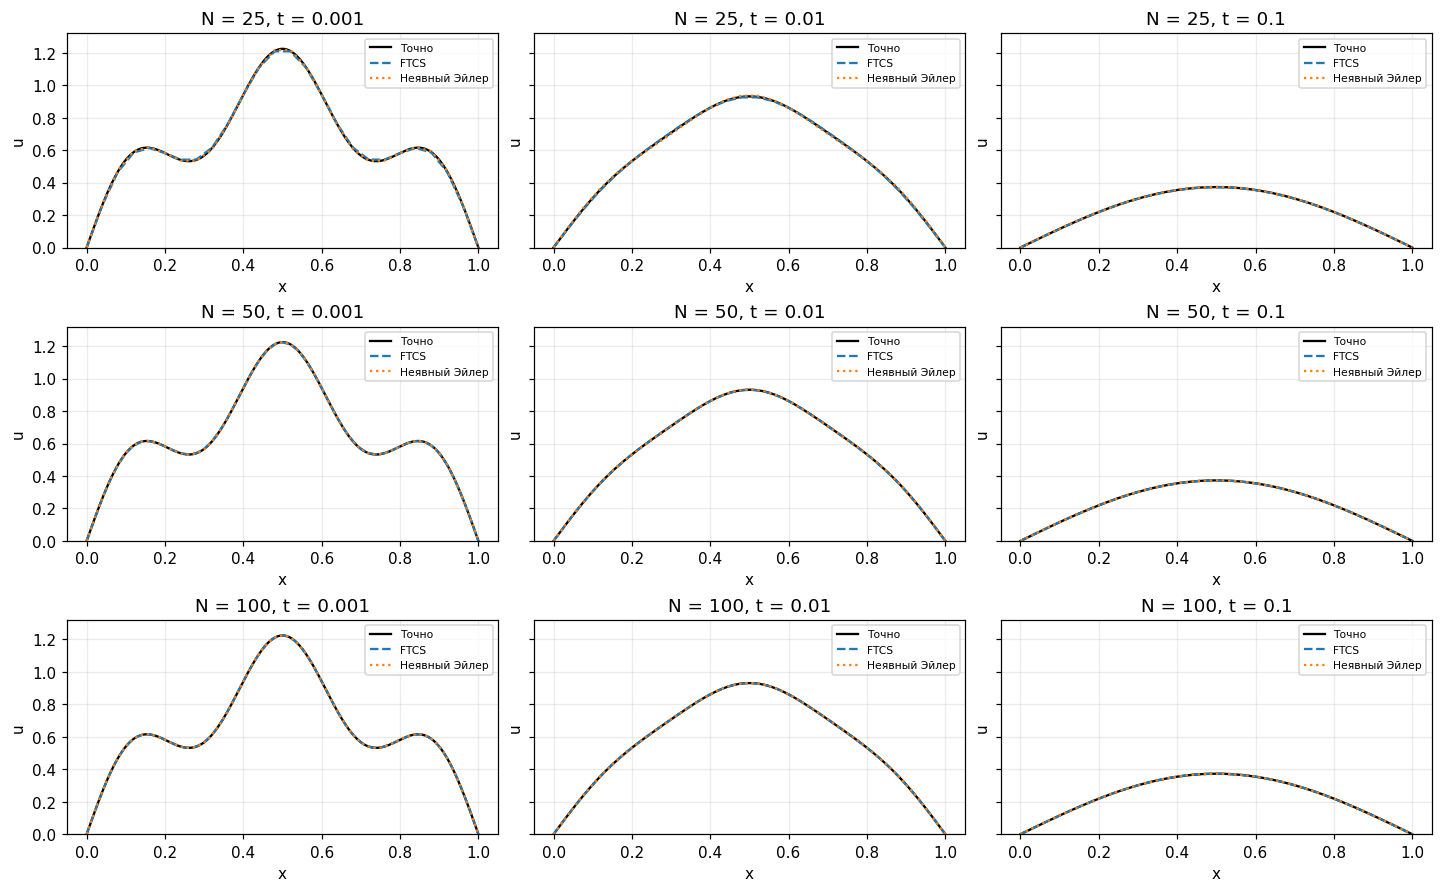

In [2]:
fig, axes = plt.subplots(3, 3, figsize=(13, 8), sharey=True, layout="constrained")
fine_x = np.linspace(0, 1, 500)
for row, N in enumerate(sizes):
    for col, t in enumerate(targets):
        ax = axes[row, col]
        ax.plot(fine_x, exact(fine_x, t), "k-", label="Точно")
        for method, style in [("FTCS", "--"), ("Неявный Эйлер", ":")]:
            x, dt, layers = runs[N, method]
            ax.plot(x, sample(layers, t, dt), style, label=method)
        ax.set(title=f"N = {N}, t = {t:g}", xlabel="x", ylabel="u", ylim=(0, 1.32))
        ax.legend(fontsize=7)
plt.show()

## 3. Ошибки и порядок сходимости

Вычисляется $E_\infty=\max_j|u_j-u(x_j,t)|$.
Оценка порядка между соседними сетками: $p=\log_2(E_N/E_{2N})$.
В таблице порядок указан относительно предыдущей, более грубой сетки.
Оба метода имеют первый порядок по времени и второй по пространству;
при $\Delta t\sim\Delta x^2$ ожидается второй порядок относительно $\Delta x$.

Метод             t         N      E_inf          p
FTCS              0.001     25     1.993728e-03   —
FTCS              0.001     50     6.476502e-04   1.622
FTCS              0.001     100    1.683629e-04   1.944
FTCS              0.01      25     2.896751e-03   —
FTCS              0.01      50     7.624927e-04   1.926
FTCS              0.01      100    1.912317e-04   1.995
FTCS              0.1       25     6.764404e-04   —
FTCS              0.1       50     1.695161e-04   1.997
FTCS              0.1       100    4.236174e-05   2.001
Неявный Эйлер     0.001     25     6.167900e-03   —
Неявный Эйлер     0.001     50     1.617491e-03   1.931
Неявный Эйлер     0.001     100    4.042878e-04   2.000
Неявный Эйлер     0.01      25     7.218189e-03   —
Неявный Эйлер     0.01      50     1.866038e-03   1.952
Неявный Эйлер     0.01      100    4.642112e-04   2.007
Неявный Эйлер     0.1       25     1.639422e-03   —
Неявный Эйлер     0.1       50     4.111727e-04   1.995
Неявный Эйлер     0.

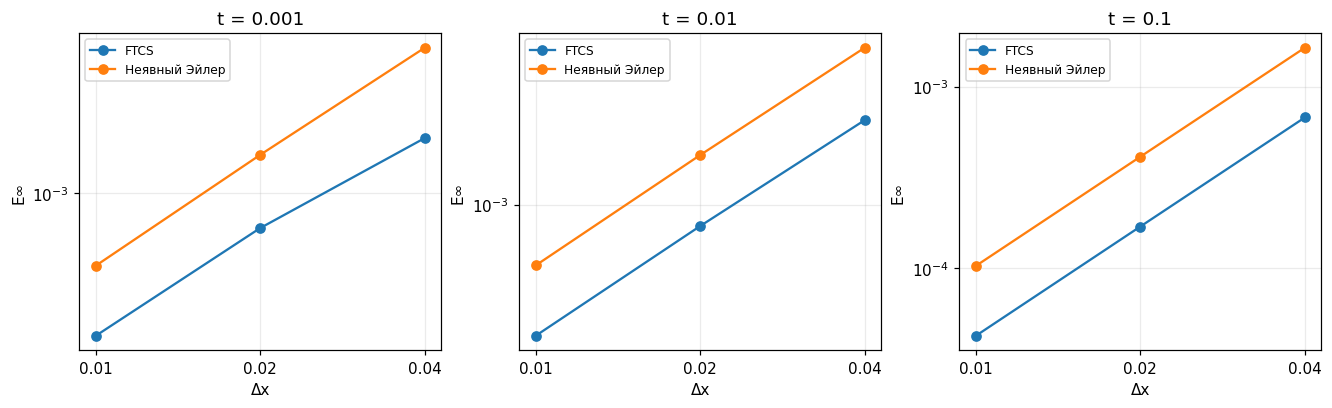

In [3]:
print("Метод             t         N      E_inf          p")
for method in ["FTCS", "Неявный Эйлер"]:
    for t in targets:
        previous = None
        for N in sizes:
            error = errors[N, method, t]
            order = "—" if previous is None else f"{np.log2(previous/error):.3f}"
            print(f"{method:<18}{t:<10g}{N:<7}{error:.6e}   {order}")
            previous = error

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
for ax, t in zip(axes, targets):
    for method in ["FTCS", "Неявный Эйлер"]:
        ax.loglog(1/np.array(sizes), [errors[N,method,t] for N in sizes], "o-", label=method)
    ax.set(title=f"t = {t:g}", xlabel="Δx", ylabel="E∞")
    ax.set_xticks([1/N for N in sizes], [str(1/N) for N in sizes])
    ax.minorticks_off()
    ax.legend(fontsize=8)
plt.show()

## Выводы

На более мелких сетках оба решения приближаются к точному. Между сетками с 50 и
100 интервалами оценки порядка составили 1.94–2.01. На первой паре сеток при
$t=0.001$ у FTCS получилось 1.62: на грубой сетке ещё заметны члены более высокого
порядка и влияние интерполяции между временными слоями.

Каждая гармоника $\sin(k\pi x)$ затухает как $e^{-k^2\pi^2t}$.
Поэтому составляющая с $k=5$ имеет в 25 раз большую скорость экспоненциального
затухания, чем составляющая с $k=1$. Её характерное время равно
$1/(25\pi^2)\approx0.00405$, а для первой гармоники — $1/\pi^2\approx0.1013$.
Мелкие детали исчезают быстрее, потому что имеют большую кривизну профиля
и сильнее изменяются под действием теплопроводности.